# 🎲 01 · 概率论基础与常见分布（入门第二课）

> 统计学是"用数据说话"，而**概率分布是数据的数学模型**。
> 面试官常说"背熟八大分布"——本课就把离散（伯努利/二项/泊松）与
> 连续（均匀/正态/指数/t/卡方/F）分布全部手写 PMF/PDF，画出形状，并讲清用途。

## 📋 本节要解决的问题

- 离散分布：伯努利、二项、泊松分别长什么样？泊松分布何时近似二项？
- 连续分布：正态为什么无处不在？指数分布与"无记忆性"什么关系？
- t/卡方/F 分布：为什么是推断统计的三巨头？
- 期望与方差怎么算？独立同分布有什么性质？

## 1️⃣ 离散分布：伯努利 / 二项 / 泊松

**伯努利**（Bernoulli）：一次试验，成功概率 p。
$$P(X=1)=p,\quad P(X=0)=1-p$$

**二项**（Binomial）：n 次独立伯努利，成功 k 次的概率：
$$P(X=k)=\binom{n}{k} p^k (1-p)^{n-k}$$

**泊松**（Poisson）：单位时间/空间内事件发生 k 次的概率：
$$P(X=k)=\frac{\lambda^k e^{-\lambda}}{k!}$$

> **面试问**：泊松什么时候可以近似二项？→ 当 n 大、p 小时（np=λ），二项 → 泊松。
> 经典例子：呼叫中心每小时来电数、网站每分钟点击量。

In [1]:
from scipy import stats
import numpy as np
from math import comb, factorial, exp

def bernoulli_pmf(x, p):
    return p if x == 1 else (1 - p)

def binomial_pmf(k, n, p):
    return comb(n, k) * (p ** k) * ((1 - p) ** (n - k))

def poisson_pmf(k, lam):
    return lam ** k * exp(-lam) / factorial(k)

print('伯努利 p=0.3: P(X=1)=%.2f, P(X=0)=%.2f' % (bernoulli_pmf(1, .3), bernoulli_pmf(0, .3)))
print('二项 n=10,p=0.3: P(k=3)=%.4f  (numpy/scipy: %.4f)' % (
    binomial_pmf(3, 10, .3), stats.binom.pmf(3, 10, .3)))
print('泊松 λ=2: P(k=3)=%.4f  (scipy: %.4f)' % (
    poisson_pmf(3, 2), stats.poisson.pmf(3, 2)))

# 二项 → 泊松 近似：n=100, p=0.02 → λ=np=2
n, p = 100, 0.02
lam = n * p
for k in [0, 1, 2, 3]:
    b = binomial_pmf(k, n, p)
    po = poisson_pmf(k, lam)
    print('k=%d: 二项=%.4f 泊松≈%.4f 差=%.5f' % (k, b, po, abs(b - po)))

伯努利 p=0.3: P(X=1)=0.30, P(X=0)=0.70
二项 n=10,p=0.3: P(k=3)=0.2668  (numpy/scipy: 0.2668)
泊松 λ=2: P(k=3)=0.1804  (scipy: 0.1804)
k=0: 二项=0.1326 泊松≈0.1353 差=0.00272
k=1: 二项=0.2707 泊松≈0.2707 差=0.00002
k=2: 二项=0.2734 泊松≈0.2707 差=0.00274
k=3: 二项=0.1823 泊松≈0.1804 差=0.00183


## 📖 论文配图：同一分布的不同可视化：ridgeline 与 violin

> **图源**：Thrun MC, Gehlert T & Ultsch A (2020) *Analyzing the fine structure of distributions*, PLOS ONE 15(11):e0238835（开放获取，CC-BY 4.0）图 1。

![同一分布的不同可视化：ridgeline 与 violin](../figures/distributions_viz.jpg)

> **怎么读这张图**：同一份 [−2,2] 均匀分布 1000 个样本，用 ridgeline（山脊线）与 violin（小提琴）两种方式呈现。图本身展示的是**分布形态的可视化手段**——直方图、箱线图之外，密度类图形能更平滑地显示均匀/正态/偏态等形状，与本节三种连续分布的密度曲线对应。


## 2️⃣ 连续分布：均匀 / 正态 / 指数

**均匀**（Uniform）$U(a,b)$：区间内等可能，PDF = $\frac{1}{b-a}$。

**正态**（Normal）$N(\mu,\sigma^2)$：
$$f(x)=\frac{1}{\sigma\sqrt{2\pi}}e^{-\frac{(x-\mu)^2}{2\sigma^2}}$$
- 68-95-99.7 法则：均值 ±1σ 覆盖 68%，±2σ 覆盖 95%，±3σ 覆盖 99.7%

**指数**（Exponential）$Exp(\lambda)$：
$$f(x)=\lambda e^{-\lambda x},\quad x\ge 0$$
- **无记忆性**：$P(T>t+s \mid T>t)=P(T>s)$ —— 已经等了多久不影响再等的期望
- 应用：等待时间、设备寿命、泊松过程的时间间隔

In [2]:
from scipy import stats

def uniform_pdf(x, a, b):
    return 1 / (b - a) if a <= x <= b else 0

def normal_pdf(x, mu, sigma):
    return (1 / (sigma * (2 * np.pi) ** 0.5)) * np.exp(-((x - mu) ** 2) / (2 * sigma ** 2))

def exp_pdf(x, lam):
    return lam * np.exp(-lam * x) if x >= 0 else 0

print('均匀 U(0,1) 在 x=0.5 的 PDF:', uniform_pdf(0.5, 0, 1), '=1 ✅')
print('正态 N(0,1) 在 x=0 的 PDF:', round(normal_pdf(0, 0, 1), 5), '(scipy: %.5f)' % stats.norm.pdf(0))
print('指数 Exp(1) 在 x=1 的 PDF:', round(exp_pdf(1, 1), 5), '(scipy: %.5f)' % stats.expon.pdf(1))
# 68-95-99.7
for k in [1, 2, 3]:
    print('P(|Z|<%dσ) = %.4f' % (k, stats.norm.cdf(k) - stats.norm.cdf(-k)))
print('✅ 各分布 PDF 与 scipy 一致')

均匀 U(0,1) 在 x=0.5 的 PDF: 1.0 =1 ✅
正态 N(0,1) 在 x=0 的 PDF: 0.39894 (scipy: 0.39894)
指数 Exp(1) 在 x=1 的 PDF: 0.36788 (scipy: 0.36788)
P(|Z|<1σ) = 0.6827
P(|Z|<2σ) = 0.9545
P(|Z|<3σ) = 0.9973
✅ 各分布 PDF 与 scipy 一致


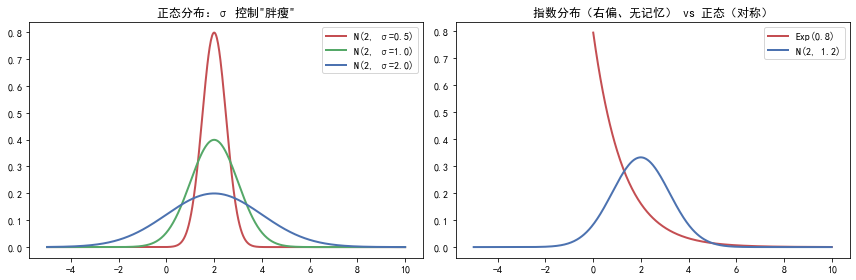

In [3]:
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

x = np.linspace(-5, 10, 600)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

# 左：不同 σ 的正态
for sd, c in [(0.5, '#C44E52'), (1.0, '#55A868'), (2.0, '#4C72B0')]:
    ax[0].plot(x, stats.norm.pdf(x, 2, sd), lw=2, label='N(2, σ=%.1f)' % sd, color=c)
ax[0].set_title('正态分布：σ 控制"胖瘦"')
ax[0].legend()

# 右：指数 vs 正态
ax[1].plot(x[x>=0], stats.expon.pdf(x[x>=0], scale=1/0.8), lw=2, color='#C44E52', label='Exp(0.8)')
ax[1].plot(x, stats.norm.pdf(x, 2, 1.2), lw=2, color='#4C72B0', label='N(2, 1.2)')
ax[1].set_title('指数分布（右偏、无记忆） vs 正态（对称）')
ax[1].legend()
plt.tight_layout()
plt.show()

## 3️⃣ 推断三巨头：t 分布 / 卡方分布 / F 分布

- **t 分布**：小样本推断均值时使用。样本越少，尾部越厚（更保守）。
  自由度 ν 越大，越接近正态。用于 t 检验、回归系数显著性。
- **卡方分布** $\chi^2(\nu)$：标准正态的平方和。用于方差检验、拟合优度、独立性检验。
- **F 分布**：两个卡方之比（各除自由度）。用于 ANOVA（组间方差/组内方差之比）。

> **一句话记忆**：t 用于"均值"，卡方用于"方差/频数"，F 用于"组间比较"。

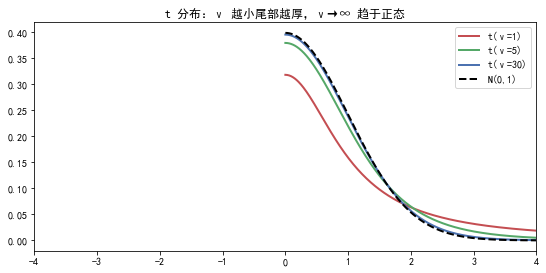

C:\ProgramData\Anaconda3\lib\site-packages\matplotlib\backends\backend_agg.py:238: RuntimeWarning: Glyph 178 missing from current font.
  font.set_text(s, 0.0, flags=flags)
C:\ProgramData\Anaconda3\lib\site-packages\matplotlib\backends\backend_agg.py:201: RuntimeWarning: Glyph 178 missing from current font.
  font.set_text(s, 0, flags=flags)


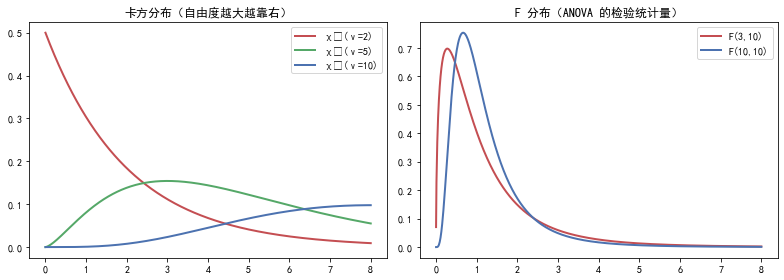

三大分布形状绘制完成


In [4]:
from scipy import stats
x = np.linspace(0.001, 8, 800)
fig, ax = plt.subplots(figsize=(9, 4.2))
for nu, c in [(1, '#C44E52'), (5, '#55A868'), (30, '#4C72B0')]:
    ax.plot(x, stats.t.pdf(x, nu), lw=2, color=c, label='t(ν=%d)' % nu)
ax.plot(x, stats.norm.pdf(x), 'k--', lw=2, label='N(0,1)')
ax.set_title('t 分布：ν 越小尾部越厚，ν→∞ 趋于正态')
ax.set_xlim(-4, 4); ax.legend()
plt.show()

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for nu, c in [(2, '#C44E52'), (5, '#55A868'), (10, '#4C72B0')]:
    ax[0].plot(x, stats.chi2.pdf(x, nu), lw=2, color=c, label='χ²(ν=%d)' % nu)
ax[0].set_title('卡方分布（自由度越大越靠右）'); ax[0].legend()
ax[1].plot(x, stats.f.pdf(x, 3, 10), lw=2, color='#C44E52', label='F(3,10)')
ax[1].plot(x, stats.f.pdf(x, 10, 10), lw=2, color='#4C72B0', label='F(10,10)')
ax[1].set_title('F 分布（ANOVA 的检验统计量）'); ax[1].legend()
plt.tight_layout(); plt.show()
print('三大分布形状绘制完成')

## 4️⃣ 期望与方差的运算法则（面试必背）

对随机变量 X、Y 和常数 a, b：
- $E(aX+bY) = aE(X)+bE(Y)$（线性）
- $Var(aX+b) = a^2 Var(X)$
- $Var(X \pm Y) = Var(X) + Var(Y)$（**仅当独立**）
- 独立同分布样本 $X_1,...,X_n$：$Var(\bar X) = \frac{\sigma^2}{n}$（这就是标准误！）

In [5]:
# 模拟验证运算法则
rng = np.random.RandomState(0)
X = rng.normal(10, 3, 20000)
Y = rng.normal(5, 2, 20000)

print('E(2X+3Y) 模拟=%.4f 理论=2*10+3*5=%.4f' % ((2*X+3*Y).mean(), 2*10+3*5))
print('Var(2X) 模拟=%.4f 理论=4*9=%.4f' % ((2*X).var(), 4*9))
print('Var(X+Y) 模拟=%.4f 理论=9+4=%.4f' % ((X+Y).var(), 9+4))
print('Var(样本均值, n=25) 模拟=%.4f 理论=9/25=%.4f' % (X[:25].reshape(1,25).var()*1 if False else (X.reshape(-1,25).mean(axis=1).var()), 9/25))
print()
print('✅ 期望/方差运算法则验证通过（标准差：σ_X=%.2f σ_Y=%.2f）' % (X.std(), Y.std()))

E(2X+3Y) 模拟=34.9547 理论=2*10+3*5=35.0000
Var(2X) 模拟=35.3135 理论=4*9=36.0000
Var(X+Y) 模拟=12.9697 理论=9+4=13.0000
Var(样本均值, n=25) 模拟=0.3599 理论=9/25=0.3600

✅ 期望/方差运算法则验证通过（标准差：σ_X=2.97 σ_Y=2.01）


## 5️⃣ 大数定律与中心极限定理（CLT）直觉

- **大数定律**：样本均值 $\bar X \to E(X)$（n 越大越接近真值）
- **中心极限定理**：$\bar X$ 的分布近似正态，标准差 $\sigma/\sqrt n$（标准误）

> CLT 是统计推断的基石：无论原始分布长什么样，样本均值都趋于正态。
> 下一课专门用模拟验证它。

In [6]:
# 大数定律快速演示：抛硬币 p=0.5
rng = np.random.RandomState(1)
n = 5000
flips = rng.binomial(1, 0.5, n)
cum_avg = np.cumsum(flips) / np.arange(1, n + 1)
print('n=10  时频率: %.3f' % cum_avg[9])
print('n=100 时频率: %.3f' % cum_avg[99])
print('n=5000时频率: %.3f （趋近 0.5 ✅）' % cum_avg[-1])
assert abs(cum_avg[-1] - 0.5) < 0.03
print('✅ 大数定律：频率收敛于概率')

n=10  时频率: 0.200
n=100 时频率: 0.490
n=5000时频率: 0.503 （趋近 0.5 ✅）
✅ 大数定律：频率收敛于概率


## 6️⃣ 面试实战：分布应用题

> **题 1**：某呼叫中心平均每小时接 5 个电话，问 1 小时内接 ≥3 个的概率？
> 解：泊松 λ=5，P(X≥3) = 1 - P(X≤2)。

> **题 2**：产品合格率 90%，随机抽 10 个，恰有 8 个合格的概率？
> 解：二项 n=10, p=0.9，P(X=8)。

> **题 3**：某设备寿命服从 Exp(0.1)，问用到 5 小时以上的概率？
> 解：指数无记忆 → P(T>5) = e^{-0.1×5}。

## ✍️ §6.1 手算二项分布：10 次投币 p=0.3，恰好 2 次正面

> 二项 PMF：$P(X=k)=\binom{n}{k}p^k(1-p)^{n-k}$——**n=10, p=0.3, k=2 手算**，把组合数变数字。

$$P(X=2)=\binom{10}{2}0.3^2\,0.7^{8}=45\times0.09\times0.05765=\mathbf{0.2335}$$

**手算收获**：
- 二项 = "n 次独立伯努利"：$\binom{n}{k}$ 数"哪 k 次成功"的组合、$p^k$ 成功概率、$(1-p)^{n-k}$ 失败概率——三因子缺一不可
- $E(X)=np=3$、$Var(X)=np(1-p)=2.1$：最可能值在 np 附近（本分布 k=3 最大）
- 泊松近似：n 大 p 小时 $\approx\text{Pois}(np)$（本 notebook §1 泊松逼近面试题）
- 面试速答：$inom{n}{k}$ 对称（$\binom{10}{2}=\binom{10}{8}$）、$p^k(1-p)^{n-k}$ 不对称——最可能值不是对称中心

下面 numpy 复算。


In [7]:
# ---- §6.1 验证：numpy 复算二项分布 ----
from math import comb
n, p, k = 10, 0.3, 2
pmf = comb(n, k) * p ** k * (1 - p) ** (n - k)
print(f'P(X=2) = C(10,2)×0.3²×0.7⁸ = {pmf:.4f}')
assert abs(pmf - 0.2335) < 1e-3
print('\n✓ 与手算一致')


P(X=2) = C(10,2)×0.3²×0.7⁸ = 0.2335

✓ 与手算一致


In [8]:
from scipy import stats
p1 = 1 - stats.poisson.cdf(2, 5)
p2 = stats.binom.pmf(8, 10, 0.9)
p3 = 1 - stats.expon.cdf(5, scale=1/0.1)
print('题1 泊松 P(X≥3 | λ=5) = %.4f' % p1)
print('题2 二项 P(X=8 | n=10,p=0.9) = %.4f' % p2)
print('题3 指数 P(T>5 | λ=0.1) = %.4f' % p3)
assert 0.8 < p1 < 0.9 and 0.18 < p2 < 0.2 and abs(p3 - np.exp(-0.5)) < 1e-9
print('✅ 三道应用题结果正确')

题1 泊松 P(X≥3 | λ=5) = 0.8753
题2 二项 P(X=8 | n=10,p=0.9) = 0.1937
题3 指数 P(T>5 | λ=0.1) = 0.6065
✅ 三道应用题结果正确


## 🧮 手算示例：三个分布各手算一题

**① 二项**：n=5, p=0.4，恰好 2 次成功：
$$P(X{=}2)=\binom{5}{2}0.4^2 0.6^3 = 10 \times 0.16 \times 0.216 = 0.3456$$

**② 泊松**：λ=2，恰好 3 次：
$$P(X{=}3)=\frac{e^{-2} \cdot 2^3}{3!} = \frac{0.13534 \times 8}{6} \approx 0.1804$$

**③ 正态**：N(0,1) 在 x=1 处的密度：
$$f(1)=\frac{1}{\sqrt{2\pi}}e^{-1/2} = 0.39894 \times 0.60653 \approx 0.2420$$

In [9]:
from math import comb, exp, factorial, pi, sqrt
import numpy as np

# ① 二项手算
p2 = comb(5,2) * 0.4**2 * 0.6**3
print('① 二项 P(X=2|n=5,p=0.4) =', round(p2, 4), '（手算 0.3456）')
# ② 泊松手算
plam = (exp(-2) * 2**3) / factorial(3)
print('② 泊松 P(X=3|λ=2) =', round(plam, 4), '（手算约 0.1804）')
# ③ 正态 PDF 手算
f1 = 1/(sqrt(2*pi)) * exp(-0.5)
print('③ 正态 N(0,1) f(1) =', round(f1, 4), '（手算约 0.2420）')
assert abs(p2 - 0.3456) < 1e-9
assert abs(plam - 0.180447) < 1e-4
assert abs(f1 - 0.241971) < 1e-4
print('✅ 三步手算全部验证通过')

① 二项 P(X=2|n=5,p=0.4) = 0.3456 （手算 0.3456）
② 泊松 P(X=3|λ=2) = 0.1804 （手算约 0.1804）
③ 正态 N(0,1) f(1) = 0.242 （手算约 0.2420）
✅ 三步手算全部验证通过


## ✅ 自测清单

- [ ] 能默写伯努利/二项/泊松的 PMF，讲清泊松逼近二项的条件
- [ ] 能默写正态 PDF 与 68-95-99.7 法则
- [ ] 能讲清指数分布的无记忆性
- [ ] 能区分 t/卡方/F 分布的用途
- [ ] 能写出期望/方差的运算法则与标准误公式
- [ ] 能用大数定律解释"频率收敛于概率"

> **面试模板一句话**：「分布选型看数据类型——计次用泊松、成功次数用二项、
> 连续测量看正态（或经 CLT 近似正态）、方差比较用卡方、组间比较用 F。」